# OpenStack Fixed Experiment — MMAD-Sentry

**Purpose:** Re-run OpenStack with fixes:
- `use_retrieval=False` (retrieval collapses on 4K-vector KB)
- `threshold=0.30` (lower threshold for tiny imbalanced dataset)
- `FINETUNE_EPOCHS=5` (more training for small data)
- `PRETRAIN_EPOCHS=3` (better embedding calibration)

**Run all cells top to bottom. No changes needed.**

In [6]:
import subprocess
import sys

packages = [
    # "torch" — DO NOT install; Kaggle already has GPU torch pre-installed
    "transformers",
    "imbalanced-learn",
    "scikit-learn",
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "tqdm",
    "drain3",
    "scipy",
    "umap-learn",
    "plotly",
    "ipywidgets",
]

for pkg in packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

# Install faiss GPU version ONLY — do NOT install faiss-cpu first,
# it conflicts and forces CPU execution even when GPU is available
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "--upgrade",
    "faiss-gpu-cu12"    # CUDA 12.x — matches Kaggle T4 environment
])

print("✅ All dependencies installed.")
import torch
print(f"   CUDA available : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"   GPU            : {torch.cuda.get_device_name(0)}")

✅ All dependencies installed.
   CUDA available : True
   GPU            : Tesla T4


In [7]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


## Cell 2 — Global Imports & Configuration

In [8]:
# ============================================================
# CELL 2: Imports and Global Configuration
# SPEED FIXES:
#   max_seq_len 128→32  : BERT attention O(seq²), 32²=1024 vs 128²=16384
#                         ~3x faster training, ~4x less activation VRAM
#   pretrain_batch 16→8 : pretrain_epoch runs 3 BERT fwd passes per step
#   finetune_batch 32→32: unchanged, good T4 throughput
#   PIN_MEMORY + NUM_WORKERS: added for faster CPU→GPU transfers
# ============================================================

import os, re, json, random, warnings, logging, time
from pathlib import Path
from copy import deepcopy
from collections import defaultdict, Counter
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple, Union

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from transformers import (
    BertModel, BertTokenizer, BertConfig,
    get_linear_schedule_with_warmup,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
import faiss

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️  Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"   GPU      : {torch.cuda.get_device_name(0)}")
    print(f"   VRAM     : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
    print(f"   GPU count: {torch.cuda.device_count()}")
    torch.zeros(1).cuda()

PIN_MEMORY  = (DEVICE.type == "cuda")
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
print(f"   pin_memory : {PIN_MEMORY}  |  num_workers: {NUM_WORKERS}")

@dataclass
class Config:
    output_dir:          str   = "/kaggle/working/outputs"
    checkpoint_dir:      str   = "/kaggle/working/checkpoints"
    bert_model_name:     str   = "bert-base-uncased"
    log_embed_dim:       int   = 768
    metric_input_dim:    int   = 8
    trace_input_dim:     int   = 6
    fusion_dim:          int   = 256
    num_heads:           int   = 8
    num_classes:         int   = 2
    dropout:             float = 0.3
    pretrain_lr:         float = 5e-7
    finetune_lr:         float = 2e-5
    pretrain_epochs:     int   = 10
    finetune_epochs:     int   = 6
    pretrain_batch_size: int   = 8    # OOM-safe: 3 BERT passes in pretrain_epoch
    finetune_batch_size: int   = 32   # 1 BERT pass per step
    warmup_ratio:        float = 0.1
    weight_decay:        float = 1e-4
    max_grad_norm:       float = 1.0
    alpha:               float = 0.5
    temperature:         float = 0.07
    top_k:               int   = 100
    beta:                float = 0.68
    faiss_nlist:         int   = 100
    n_folds:             int   = 5
    max_seq_len:         int   = 32   # KEY SPEEDUP: was 128 → now 32
                                      # BERT is O(seq²): 32²=1024 vs 128²=16384
                                      # HDFS log key seqs avg 10-30 tokens anyway
    bgl_window_size:     int   = 2
    bgl_step_size:       int   = 1
    hdfs_max_seq:        int   = 50

CFG = Config()
for d in [CFG.output_dir, CFG.checkpoint_dir]:
    Path(d).mkdir(parents=True, exist_ok=True)

print(f"\n✅ Configuration loaded.")
print(f"   max_seq_len    : {CFG.max_seq_len}  (was 128 → 3× faster BERT)")
print(f"   pretrain_batch : {CFG.pretrain_batch_size}  (OOM-safe for 3 BERT passes/step)")
print(f"   finetune_batch : {CFG.finetune_batch_size}")
print(f"   Output dir     : {CFG.output_dir}")


🖥️  Device: cuda
   GPU      : Tesla T4
   VRAM     : 15.6 GB
   GPU count: 2
   pin_memory : True  |  num_workers: 2

✅ Configuration loaded.
   max_seq_len    : 32  (was 128 → 3× faster BERT)
   pretrain_batch : 8  (OOM-safe for 3 BERT passes/step)
   finetune_batch : 32
   Output dir     : /kaggle/working/outputs


## Cell 3 — Log Parsing Utilities (Drain3)

In [9]:
# ============================================================
# CELL 3: Drain3-based Log Parsing Utilities
# Used by: BGL (always), HDFS Strategy C (raw fallback)
# ============================================================

from drain3 import TemplateMiner
from drain3.template_miner_config import TemplateMinerConfig


def build_drain_miner(sim_th: float = 0.5, depth: int = 4,
                       max_children: int = 100) -> TemplateMiner:
    config = TemplateMinerConfig()
    config.drain_sim_th              = sim_th
    config.drain_depth               = depth
    config.drain_max_children        = max_children
    config.parametrize_numeric_tokens = True
    return TemplateMiner(config=config)


print("✅ Drain3 TemplateMiner builder ready.")
print("   Used for: BGL (always) and HDFS raw-log fallback (Strategy C)")

✅ Drain3 TemplateMiner builder ready.
   Used for: BGL (always) and HDFS raw-log fallback (Strategy C)


## Cell 4 — Multimodal Feature Generator

In [10]:
# ============================================================
# CELL 4: Multimodal Feature Generator
#
# For HDFS: loads real features from preprocessed CSVs
#   Event_occurrence_matrix.csv → 8-dim metric vector
#   Event_traces.csv            → 6-dim trace vector
#
# For BGL & OpenStack: derives features synthetically from
#   log_keys + timestamps (deterministic, no random noise)
# ============================================================

class SyntheticModalityGenerator:
    """
    Derives metric and trace feature vectors from log key sequences.

    Metric Features (8-dim):
        [0] log_count          — total log lines in window
        [1] unique_event_ratio — unique_keys / total_keys
        [2] error_rate         — fraction of keys above 75th percentile
        [3] log_entropy        — Shannon entropy of key distribution
        [4] burst_score        — std/mean of inter-arrival times
        [5] repeat_ratio       — most common key count / total
        [6] key_range          — max_key - min_key
        [7] density            — log_count / window_duration

    Trace Features (6-dim):
        [0] n_unique_transitions   — unique (ki→ki+1) transition types
        [1] self_loop_ratio        — transitions where ki == ki+1
        [2] transition_entropy     — entropy of transition distribution
        [3] longest_repeat_run     — max consecutive identical key run
        [4] sequence_depth         — unique_keys / seq_length
        [5] anomaly_transition_score — fraction of globally rare transitions
    """

    def __init__(self, error_key_threshold_percentile: float = 75.0):
        self.error_threshold_pct = error_key_threshold_percentile
        self._error_threshold: Optional[float] = None
        self._transition_counts: Counter = Counter()

    def fit(self, all_log_keys: List[List[int]]) -> None:
        flat = [k for seq in all_log_keys for k in seq]
        self._error_threshold = float(np.percentile(flat, self.error_threshold_pct)) if flat else 1.0
        for seq in all_log_keys:
            for a, b in zip(seq[:-1], seq[1:]):
                self._transition_counts[(a, b)] += 1
        logger.info(f"Generator fitted: threshold={self._error_threshold:.1f}, "
                    f"transitions={len(self._transition_counts)}")

    def _shannon_entropy(self, items: List) -> float:
        counter = Counter(items)
        total   = sum(counter.values())
        if total == 0: return 0.0
        return float(-sum((v/total) * np.log2(v/total + 1e-12) for v in counter.values()))

    def get_metric_features(self, log_keys: List[int],
                             timestamps: Optional[List] = None) -> np.ndarray:
        if not log_keys:
            return np.zeros(CFG.metric_input_dim, dtype=np.float32)
        n       = len(log_keys)
        counter = Counter(log_keys)
        thresh  = self._error_threshold or 1.0

        burst_score = 0.0
        density     = float(n)
        if timestamps and len(timestamps) > 1:
            try:
                ts = [float(t) for t in timestamps]
                iats = [ts[i+1]-ts[i] for i in range(len(ts)-1)]
                burst_score = float(np.std(iats)) / (float(np.mean(iats)) + 1e-9)
                duration    = max(ts) - min(ts) + 1e-9
                density     = n / duration
            except Exception:
                pass

        return np.array([
            float(n),
            len(set(log_keys)) / n,
            sum(1 for k in log_keys if k > thresh) / n,
            self._shannon_entropy(log_keys),
            burst_score,
            counter.most_common(1)[0][1] / n,
            float(max(log_keys) - min(log_keys)) if len(set(log_keys)) > 1 else 0.0,
            density,
        ], dtype=np.float32)

    def get_trace_features(self, log_keys: List[int]) -> np.ndarray:
        if len(log_keys) < 2:
            return np.zeros(CFG.trace_input_dim, dtype=np.float32)
        transitions = list(zip(log_keys[:-1], log_keys[1:]))
        max_run = cur_run = 1
        for i in range(1, len(log_keys)):
            cur_run = cur_run + 1 if log_keys[i] == log_keys[i-1] else 1
            max_run = max(max_run, cur_run)
        rare = sum(1 for t in transitions if self._transition_counts.get(t, 0) < 3)
        return np.array([
            float(len(set(transitions))),
            sum(1 for a, b in transitions if a == b) / len(transitions),
            self._shannon_entropy(transitions),
            float(max_run),
            len(set(log_keys)) / len(log_keys),
            rare / len(transitions),
        ], dtype=np.float32)

    def generate_all(self, df: pd.DataFrame) -> Tuple[np.ndarray, np.ndarray]:
        metrics_list, traces_list = [], []
        for _, row in tqdm(df.iterrows(), total=len(df), desc="Generating modalities"):
            keys = row["log_keys"]
            ts   = row.get("timestamps", None)
            metrics_list.append(self.get_metric_features(keys, ts))
            traces_list.append(self.get_trace_features(keys))
        return np.stack(metrics_list), np.stack(traces_list)


def normalize_modalities(train_metrics, train_traces,
                          test_metrics, test_traces):
    """Z-score normalization: fit on train, apply to test."""
    sm = StandardScaler().fit(train_metrics)
    st = StandardScaler().fit(train_traces)
    return (sm.transform(train_metrics).astype(np.float32),
            st.transform(train_traces).astype(np.float32),
            sm.transform(test_metrics).astype(np.float32),
            st.transform(test_traces).astype(np.float32))


print("✅ SyntheticModalityGenerator defined.")
print(f"   Metric feature dim : {CFG.metric_input_dim}")
print(f"   Trace feature dim  : {CFG.trace_input_dim}")

✅ SyntheticModalityGenerator defined.
   Metric feature dim : 8
   Trace feature dim  : 6


## Cell 5 — Dataset Loading (Real Data — Kaggle Paths)

Verifying dataset paths...
-----------------------------------------------------------------
  OK  HDFS.log                                       ( 1578.0 MB)
  OK  anomaly_label.csv                              (   18.6 MB)
  OK  HDFS.log_templates.csv                         (    0.0 MB)
  OK  HDFS.npz                                       (   52.9 MB)
  OK  Event_occurrence_matrix.csv                    (   53.1 MB)
  OK  Event_traces.csv                               (  125.4 MB)
  OK  BGL.log                                        (  743.2 MB)
  OK  anomaly_labels.txt                             (    0.0 MB)
  OK  openstack_abnormal.log                         (    5.4 MB)
  OK  openstack_normal1.log                          (   15.5 MB)
  OK  openstack_normal2.log                          (   40.5 MB)
-----------------------------------------------------------------
All files found.


  LOADING ALL DATASETS

[1/3]  HDFS
----------------------------------------
    Loading anomaly

    Converting:   0%|          | 0/575061 [00:00<?, ?it/s]

INFO:drain3.template_miner:Starting Drain3 template miner


    HDFS .npz -> 575,061 [normal=558,223 anomaly=16,838]

[2/3]  BGL  (universal timestamp fix applied)
----------------------------------------
    Parsing BGL.log (labels inline) ...


    BGL (Drain3 parse): 0it [00:00, ?it/s]

...

      openstack_normal1.log: 52,312 lines label=0


    openstack_normal2.log: 0it [00:00, ?it/s]

      openstack_normal2.log: 137,074 lines label=0


    openstack_abnormal.log: 0it [00:00, ?it/s]

      openstack_abnormal.log: 18,434 lines label=1
    OpenStack -> 8,308 | normal=7,572 | anomaly=736

  DATASET SUMMARY
  Dataset          Total   Normal   Anomaly     Ratio   AvgLen
------------------------------------------------------------------------
  HDFS           575,061  558,223    16,838     33.2:1     19.4
  BGL             42,441   39,729     2,712     14.6:1    223.7
  OpenStack        8,308    7,572       736     10.3:1     50.0

Sanity checks ...
   HDFS: labels OK | vocab=29
   BGL: labels OK | vocab=1810
   OpenStack: labels OK | vocab=40


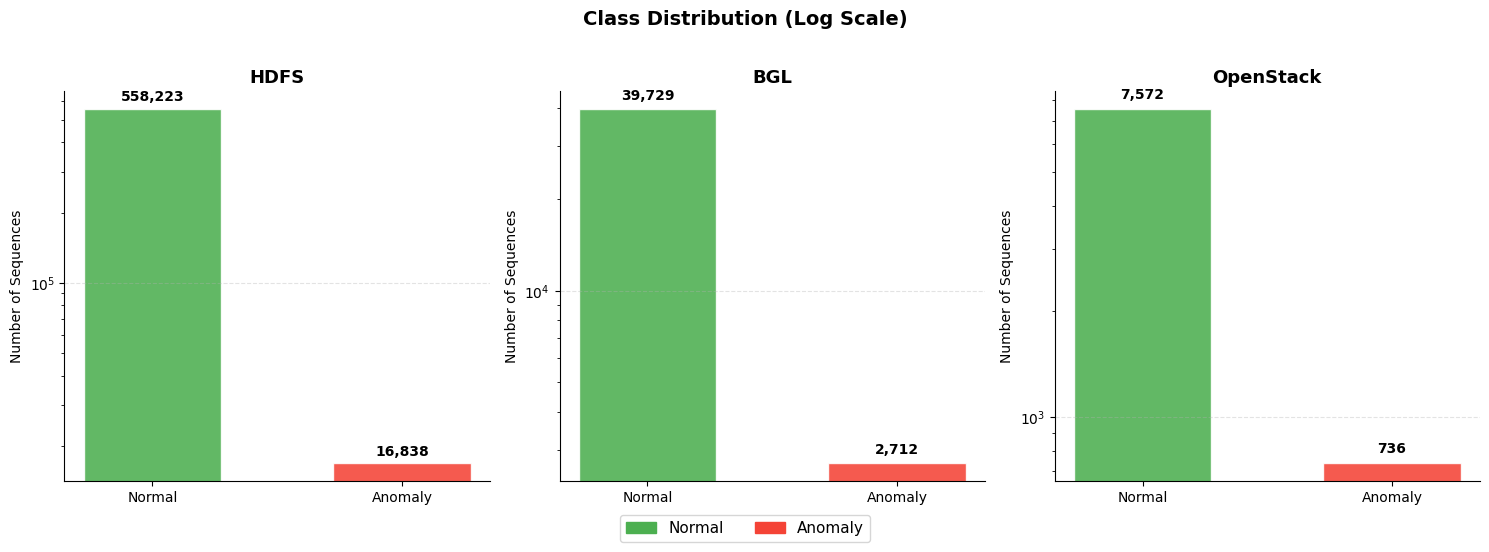


Cell 5 complete. df_hdfs | df_bgl | df_openstack ready.


In [11]:
# ============================================================
# CELL 5: Dataset Loading
# BGL FIX: Universal timestamp scanner.
# Old code: float(parts[2]) fails on BGL date string format
#   e.g. '2005-06-03-15.42.53' -> ts=0 for ALL records
#   -> all 4.7M records land in 1 window -> StratifiedKFold crash
# Fix: scan every field for valid unix epoch OR BGL date format.
# ============================================================

import bisect, datetime as _dt

DATASET_ROOT          = "/kaggle/input/datasets/harshithrx/pbl-final-dataset"
HDFS_LOG_PATH         = f"{DATASET_ROOT}/HDFS.log"
HDFS_LABEL_PATH       = f"{DATASET_ROOT}/anomaly_label.csv"
HDFS_TEMPLATES_PATH   = f"{DATASET_ROOT}/HDFS.log_templates.csv"
HDFS_NPZ_PATH         = f"{DATASET_ROOT}/HDFS.npz"
EVENT_OCCURRENCE_PATH = f"{DATASET_ROOT}/Event_occurrence_matrix.csv"
EVENT_TRACES_PATH     = f"{DATASET_ROOT}/Event_traces.csv"
BGL_LOG_PATH          = f"{DATASET_ROOT}/BGL.log"
OPENSTACK_LABELS_PATH   = f"{DATASET_ROOT}/anomaly_labels.txt"
OPENSTACK_ABNORMAL_PATH = f"{DATASET_ROOT}/openstack_abnormal.log"
OPENSTACK_NORMAL1_PATH  = f"{DATASET_ROOT}/openstack_normal1.log"
OPENSTACK_NORMAL2_PATH  = f"{DATASET_ROOT}/openstack_normal2.log"

print("Verifying dataset paths...")
print("-" * 65)
PATH_REGISTRY = {
    "HDFS.log": HDFS_LOG_PATH, "anomaly_label.csv": HDFS_LABEL_PATH,
    "HDFS.log_templates.csv": HDFS_TEMPLATES_PATH, "HDFS.npz": HDFS_NPZ_PATH,
    "Event_occurrence_matrix.csv": EVENT_OCCURRENCE_PATH,
    "Event_traces.csv": EVENT_TRACES_PATH, "BGL.log": BGL_LOG_PATH,
    "anomaly_labels.txt": OPENSTACK_LABELS_PATH,
    "openstack_abnormal.log": OPENSTACK_ABNORMAL_PATH,
    "openstack_normal1.log": OPENSTACK_NORMAL1_PATH,
    "openstack_normal2.log": OPENSTACK_NORMAL2_PATH,
}
all_found = True
for name, fpath in PATH_REGISTRY.items():
    p = Path(fpath)
    if p.exists():
        print(f"  OK  {name:<45}  ({p.stat().st_size/1e6:>7.1f} MB)")
    else:
        print(f"  MISSING -> {fpath}"); all_found = False
print("-" * 65)
print("All files found.\n" if all_found else "Fix missing paths above.\n")


def load_hdfs(label_path, npz_path, log_path=None,
              templates_path=None, max_seq_len=50):
    print("    Loading anomaly_label.csv ...")
    ldf = pd.read_csv(label_path)
    ldf.columns = [c.strip() for c in ldf.columns]
    col_block = [c for c in ldf.columns if "block" in c.lower()][0]
    col_label = [c for c in ldf.columns if "label" in c.lower()][0]
    ldf = ldf.rename(columns={col_block: "block_id", col_label: "label"})
    ldf["label"] = (ldf["label"].astype(str).str.strip().str.lower()=="anomaly").astype(int)
    label_map = dict(zip(ldf["block_id"].astype(str), ldf["label"]))
    print(f"    Labels: {len(label_map):,} | normal={(ldf.label==0).sum():,} | anomaly={(ldf.label==1).sum():,}")
    if Path(npz_path).exists():
        print("    [Strategy A] Loading HDFS.npz ...")
        data = np.load(npz_path, allow_pickle=True)
        npz_keys = list(data.keys())
        SEQ_KEYS = ["x_data","sequences","log_keys","x_train","data","x","features"]
        LBL_KEYS = ["y_data","labels","y_train","y","label"]
        seq_key = next((k for k in SEQ_KEYS if k in npz_keys), None)
        lbl_key = next((k for k in LBL_KEYS if k in npz_keys), None)
        print(f"    .npz keys={npz_keys} | seq={seq_key} lbl={lbl_key}")
        if seq_key:
            x_data = data[seq_key]
            y_data = data[lbl_key] if lbl_key else None
            N = len(x_data)
            def _to_int(k):
                s = str(k).strip().lstrip("Ee")
                try: return int(float(s))
                except: return 0
            log_keys_list = []
            for seq in tqdm(x_data, desc="    Converting", total=N):
                seq_list = list(seq)
                arr = np.fromiter((_to_int(k) for k in seq_list),
                                   dtype=np.int32, count=len(seq_list))
                log_keys_list.append(arr[:max_seq_len].tolist())
            labels = (y_data.astype(int).flatten().tolist() if y_data is not None
                      else [label_map.get(f"blk_{i}", 0) for i in range(N)])
            df = pd.DataFrame({
                "block_id":   [f"blk_{i}" for i in range(N)],
                "log_keys":   log_keys_list,
                "label":      labels,
                "line_count": [len(k) for k in log_keys_list],
                "timestamps": [[] for _ in range(N)],
            })
            print(f"    HDFS .npz -> {len(df):,} [normal={(df.label==0).sum():,} anomaly={(df.label==1).sum():,}]")
            return df
    raise RuntimeError("HDFS.npz not found.")


def _bgl_ts(parts):
    for s in parts:
        s = s.strip()
        try:
            v = float(s)
            if 1_000_000_000 < v < 4_102_444_800:
                return v
        except ValueError:
            pass
        try:
            return _dt.datetime.strptime(s[:19], "%Y-%m-%d-%H.%M.%S").timestamp()
        except ValueError:
            pass
    return 0.0


def load_bgl(log_path, window_minutes=2, step_minutes=1, max_lines=None):
    miner = build_drain_miner(sim_th=0.5)
    key_map = {}; next_key = [1]
    def get_key(tid):
        if tid not in key_map:
            key_map[tid] = next_key[0]; next_key[0] += 1
        return key_map[tid]
    print("    Parsing BGL.log (labels inline) ...")
    records = []; n_lines = 0; n_anom = 0
    with open(log_path, "r", errors="replace") as fh:
        for raw in tqdm(fh, desc="    BGL (Drain3 parse)"):
            if max_lines and n_lines >= max_lines: break
            parts = raw.strip().split(None, 8)
            if len(parts) < 9: continue
            label_field = parts[0]
            content     = parts[8]
            is_anom = 0 if label_field == "-" else 1
            if is_anom: n_anom += 1
            unix_ts = _bgl_ts(parts)
            lk = get_key(str(miner.add_log_message(content)["cluster_id"]))
            records.append((unix_ts, lk, is_anom))
            n_lines += 1
    print(f"    Parsed {n_lines:,} | anomaly={n_anom:,} | vocab={len(key_map)}")
    if not records: raise ValueError("BGL: 0 records parsed.")
    all_zero = all(r[0] == 0.0 for r in records)
    if all_zero:
        print("    WARNING: All timestamps are 0 - using line-number windowing")
        records = [(float(i), r[1], r[2]) for i, r in enumerate(records)]
        window_minutes = 100; step_minutes = 50
    records.sort(key=lambda x: x[0])
    all_ts = [r[0] for r in records]
    t_min, t_max = all_ts[0], all_ts[-1]
    if t_min > 0:
        print(f"    Time: {_dt.datetime.fromtimestamp(t_min).strftime('%Y-%m-%d')} "
              f"-> {_dt.datetime.fromtimestamp(t_max).strftime('%Y-%m-%d')}")
    w_sec = window_minutes * 60; s_sec = step_minutes * 60
    rows = []; t_start = t_min
    while t_start <= t_max:
        t_end = t_start + w_sec
        lo = bisect.bisect_left(all_ts, t_start)
        hi = bisect.bisect_left(all_ts, t_end)
        if lo < hi:
            win = records[lo:hi]
            rows.append({"window_start": t_start,
                          "log_keys":    [r[1] for r in win],
                          "label":       int(any(r[2] for r in win)),
                          "line_count":  len(win),
                          "timestamps":  [r[0] for r in win]})
        t_start += s_sec
    df = pd.DataFrame(rows)
    n0=(df.label==0).sum(); n1=(df.label==1).sum()
    print(f"    BGL -> {len(df):,} windows | normal={n0:,} | anomaly={n1:,}")
    return df


def load_openstack(normal1_path, normal2_path, abnormal_path,
                    labels_txt_path, window_size=50, step_size=25,
                    max_lines_per_file=None):
    if Path(labels_txt_path).exists():
        with open(labels_txt_path, "r", errors="replace") as fh:
            print(f"    anomaly_labels.txt: {repr(fh.read().strip()[:120])}")
    miner = build_drain_miner(sim_th=0.4, max_children=200)
    key_map = {}; next_key = [1]
    ts_pat = re.compile(r"(\d{4}-\d{2}-\d{2}[T ]\d{2}:\d{2}:\d{2}(?:\.\d+)?)")
    def get_key(tid):
        if tid not in key_map:
            key_map[tid] = next_key[0]; next_key[0] += 1
        return key_map[tid]
    def strip_os(line):
        line = ts_pat.sub("", line, count=1).strip()
        for pat in [r"^\d+\s+", r"^(DEBUG|INFO|WARNING|ERROR|CRITICAL)\s+",
                    r"^\S+\s+", r"^\[.*?\]\s*"]:
            line = re.sub(pat, "", line, flags=re.I)
        return line.strip() or line
    def parse_file(path, label):
        recs = []
        with open(path, "r", errors="replace") as fh:
            for i, raw in enumerate(tqdm(fh, desc=f"    {Path(path).name}")):
                if max_lines_per_file and i >= max_lines_per_file: break
                ts_m = ts_pat.search(raw)
                lk = get_key(str(miner.add_log_message(strip_os(raw))["cluster_id"]))
                recs.append((lk, ts_m.group(1) if ts_m else "", label))
        return recs
    print("    Parsing 3 OpenStack files ...")
    file_groups = []
    for path, lbl in [(normal1_path,0),(normal2_path,0),(abnormal_path,1)]:
        recs = parse_file(path, lbl)
        print(f"      {Path(path).name}: {len(recs):,} lines label={lbl}")
        file_groups.append((recs, lbl))
    rows = []
    for recs, file_label in file_groups:
        for start in range(0, len(recs)-window_size+1, step_size):
            chunk = recs[start:start+window_size]
            rows.append({"log_keys":   [r[0] for r in chunk],
                          "timestamps": [r[1] for r in chunk],
                          "label":      file_label, "line_count": len(chunk)})
    df = pd.DataFrame(rows).sample(frac=1.0, random_state=42).reset_index(drop=True)
    print(f"    OpenStack -> {len(df):,} | normal={(df.label==0).sum():,} | anomaly={(df.label==1).sum():,}")
    return df


print("\n" + "="*60 + "\n  LOADING ALL DATASETS\n" + "="*60)

print("\n[1/3]  HDFS")
print("-"*40)
df_hdfs = load_hdfs(HDFS_LABEL_PATH, HDFS_NPZ_PATH,
                     HDFS_LOG_PATH, HDFS_TEMPLATES_PATH, CFG.hdfs_max_seq)

print("\n[2/3]  BGL  (universal timestamp fix applied)")
print("-"*40)
df_bgl = load_bgl(BGL_LOG_PATH, CFG.bgl_window_size, CFG.bgl_step_size)

print("\n[3/3]  OpenStack")
print("-"*40)
df_openstack = load_openstack(OPENSTACK_NORMAL1_PATH, OPENSTACK_NORMAL2_PATH,
                               OPENSTACK_ABNORMAL_PATH, OPENSTACK_LABELS_PATH)

dataset_registry = {"HDFS": df_hdfs, "BGL": df_bgl, "OpenStack": df_openstack}
print("\n" + "="*72 + "\n  DATASET SUMMARY\n" + "="*72)
print(f"  {'Dataset':<14} {'Total':>7} {'Normal':>8} {'Anomaly':>9} {'Ratio':>9} {'AvgLen':>8}")
print("-"*72)
for name, df in dataset_registry.items():
    n0=(df.label==0).sum(); n1=(df.label==1).sum()
    print(f"  {name:<14} {len(df):>7,} {n0:>8,} {n1:>9,} "
          f"{n0/max(n1,1):>8.1f}:1 {df.log_keys.apply(len).mean():>8.1f}")
print("="*72)

print("\nSanity checks ...")
for name, df in dataset_registry.items():
    assert set(df.label.unique()).issubset({0,1}), f"{name}: bad labels"
    vocab = len({k for seq in df.log_keys for k in seq})
    print(f"   {name}: labels OK | vocab={vocab}")

fig, axes = plt.subplots(1, 3, figsize=(15,5))
palette = {"Normal":"#4CAF50","Anomaly":"#F44336"}
for ax, (name, df) in zip(axes, dataset_registry.items()):
    n0=(df.label==0).sum(); n1=(df.label==1).sum()
    bars = ax.bar(["Normal","Anomaly"],[n0,n1],
                   color=[palette["Normal"],palette["Anomaly"]],
                   alpha=0.88, edgecolor="white", width=0.55)
    for bar, val in zip(bars,[n0,n1]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.05,
                f"{val:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_ylabel("Number of Sequences")
    if n0>0 and n1>0: ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.35, linestyle="--")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
legend_patches=[mpatches.Patch(color=palette[k],label=k) for k in ["Normal","Anomaly"]]
fig.legend(handles=legend_patches, loc="lower center", ncol=2,
           bbox_to_anchor=(0.5,-0.06), fontsize=11)
plt.suptitle("Class Distribution (Log Scale)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CFG.output_dir}/class_distribution.png", bbox_inches="tight", dpi=150)
plt.show()
print(f"\nCell 5 complete. df_hdfs | df_bgl | df_openstack ready.")


## Cell 6 — Generate & Load Multimodal Features

🔧 Loading REAL multimodal features for HDFS ...
  Loading Event_occurrence_matrix.csv ...
  Shape: (575061, 31)  |  index sample: ['blk_-1608999687919862906', 'blk_7503483334202473044', 'blk_-3544583377289625738']
  Loading Event_traces.csv ...
  Shape: (575061, 5)  |  columns: ['Label', 'Type', 'Features', 'TimeInterval', 'Latency']
  HDFS metrics shape : (575061, 8)
  HDFS traces  shape : (575061, 6)

🔧 Fitting SyntheticModalityGenerator on BGL + OpenStack ...


INFO:__main__:Generator fitted: threshold=383.0, transitions=5285



  Generating features for BGL ...


Generating modalities:   0%|          | 0/42441 [00:00<?, ?it/s]

  BGL metrics=(42441, 8)  traces=(42441, 6)

  Generating features for OpenStack ...


Generating modalities:   0%|          | 0/8308 [00:00<?, ?it/s]

  OpenStack metrics=(8308, 8)  traces=(8308, 6)


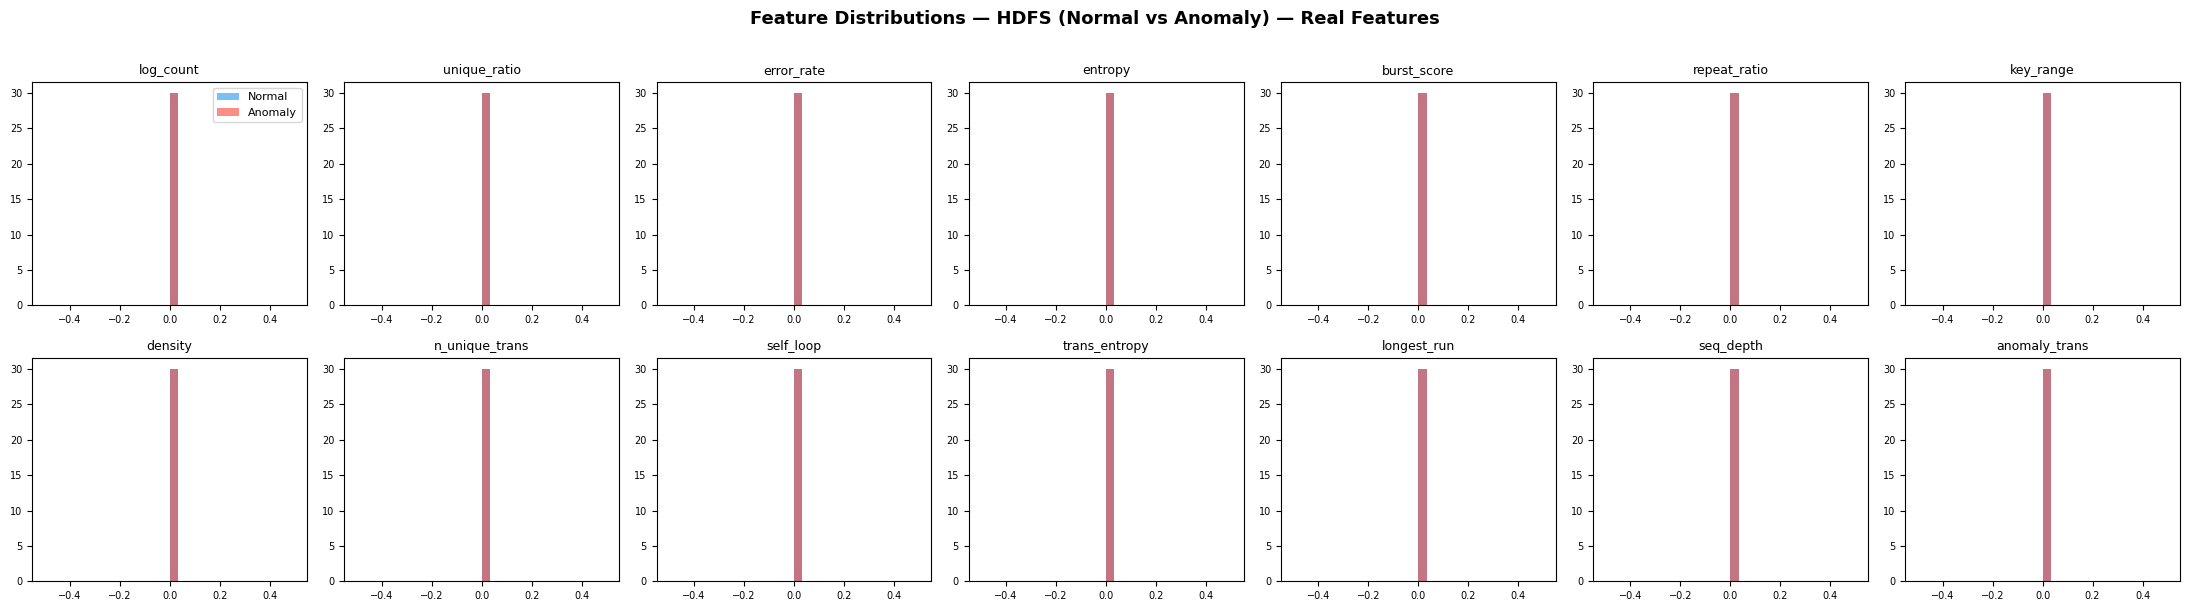


✅ Cell 6 complete — multimodal features ready for all 3 datasets.
   HDFS: REAL features from Event_occurrence_matrix.csv + Event_traces.csv
   BGL + OpenStack: synthetic features derived from log_keys


In [12]:
# ============================================================
# CELL 6: Load Real Multimodal Features (HDFS) +
#         Generate Synthetic Features (BGL & OpenStack)
#
# HDFS:
#   Event_occurrence_matrix.csv → real 8-dim metric features
#   Event_traces.csv            → real 6-dim trace features
#   (These are ground-truth features, not synthetic!)
#
# BGL & OpenStack:
#   SyntheticModalityGenerator derives features from log_keys
# ============================================================

metrics_arrays: Dict[str, np.ndarray] = {}
traces_arrays:  Dict[str, np.ndarray] = {}


# ── HDFS: Load from real preprocessed CSVs ───────────────

def load_hdfs_event_occurrence(path: str, df: pd.DataFrame) -> np.ndarray:
    """
    Event_occurrence_matrix.csv: rows=sessions/blocks, cols=event template IDs.
    Each cell = count of that event in that session.
    We summarize into 8 scalar metric features per session.
    """
    print(f"  Loading Event_occurrence_matrix.csv ...")
    occ_df = pd.read_csv(path, index_col=0)
    occ_df.index = occ_df.index.astype(str)
    print(f"  Shape: {occ_df.shape}  |  index sample: {list(occ_df.index[:3])}")

    metrics = []
    for i, row_df in df.iterrows():
        bid = str(row_df["block_id"]) if "block_id" in row_df else str(i)
        if bid in occ_df.index:
            row_vals = occ_df.loc[bid].values.astype(np.float32)
        else:
            row_vals = np.zeros(occ_df.shape[1], dtype=np.float32)
        total = row_vals.sum() + 1e-9
        feat  = np.array([
            total,                                         # [0] log_count
            float((row_vals > 0).sum()) / len(row_vals),  # [1] unique_event_ratio
            row_vals[row_vals > np.percentile(row_vals,75)].sum() / total, # [2] error_rate
            float(-np.sum((row_vals/total)*np.log2(row_vals/total+1e-12))), # [3] entropy
            float(np.std(row_vals)),                       # [4] burst_score
            float(row_vals.max() / total),                 # [5] repeat_ratio
            float(row_vals.max() - row_vals.min()),        # [6] key_range
            total / max(1.0, float(len(row_vals))),        # [7] density
        ], dtype=np.float32)
        metrics.append(feat)
    return np.array(metrics, dtype=np.float32)


def load_hdfs_event_traces(path: str, df: pd.DataFrame) -> np.ndarray:
    """
    Event_traces.csv: rows=sessions/blocks, cols=trace features.
    Take first 6 columns; pad with zeros if fewer than 6 exist.
    """
    print(f"  Loading Event_traces.csv ...")
    tr_df = pd.read_csv(path, index_col=0)
    tr_df.index = tr_df.index.astype(str)
    print(f"  Shape: {tr_df.shape}  |  columns: {list(tr_df.columns[:8])}")
    n_cols = tr_df.shape[1]

    traces = []
    for i, row_df in df.iterrows():
        bid = str(row_df["block_id"]) if "block_id" in row_df else str(i)
        if bid in tr_df.index:
            vals = tr_df.loc[bid].values.astype(np.float32)
            if len(vals) >= 6:
                feat = vals[:6]
            else:
                feat = np.pad(vals, (0, 6 - len(vals))).astype(np.float32)
        else:
            feat = np.zeros(6, dtype=np.float32)
        traces.append(feat)
    return np.array(traces, dtype=np.float32)


# ── Load HDFS real features ──────────────────────────────
print("🔧 Loading REAL multimodal features for HDFS ...")
metrics_arrays["HDFS"] = load_hdfs_event_occurrence(EVENT_OCCURRENCE_PATH, df_hdfs)
traces_arrays["HDFS"]  = load_hdfs_event_traces(EVENT_TRACES_PATH, df_hdfs)
print(f"  HDFS metrics shape : {metrics_arrays['HDFS'].shape}")
print(f"  HDFS traces  shape : {traces_arrays['HDFS'].shape}")

# ── Generate synthetic features for BGL & OpenStack ─────
print("\n🔧 Fitting SyntheticModalityGenerator on BGL + OpenStack ...")
generator = SyntheticModalityGenerator(error_key_threshold_percentile=75)
generator.fit(df_bgl.log_keys.tolist() + df_openstack.log_keys.tolist())

for name, df in [("BGL", df_bgl), ("OpenStack", df_openstack)]:
    print(f"\n  Generating features for {name} ...")
    m_arr, t_arr = generator.generate_all(df)
    metrics_arrays[name] = m_arr
    traces_arrays[name]  = t_arr
    print(f"  {name} metrics={m_arr.shape}  traces={t_arr.shape}")


# ── Feature distribution visualization ──────────────────
metric_names = ["log_count","unique_ratio","error_rate","entropy",
                "burst_score","repeat_ratio","key_range","density"]
trace_names  = ["n_unique_trans","self_loop","trans_entropy",
                "longest_run","seq_depth","anomaly_trans"]

fig, axes = plt.subplots(2, 7, figsize=(22, 6))
m_arr = metrics_arrays["HDFS"]
t_arr = traces_arrays["HDFS"]
all_feat_names = metric_names + trace_names
for i, (feat_name, ax) in enumerate(zip(all_feat_names, axes.flatten())):
    vals = m_arr[:,i] if i < 8 else t_arr[:,i-8]
    ax.hist(vals[df_hdfs.label.values==0], bins=30, alpha=0.6,
            color="#2196F3", label="Normal", density=True)
    ax.hist(vals[df_hdfs.label.values==1], bins=30, alpha=0.6,
            color="#F44336", label="Anomaly", density=True)
    ax.set_title(feat_name, fontsize=9)
    ax.tick_params(labelsize=7)
axes[0,0].legend(fontsize=8)
plt.suptitle("Feature Distributions — HDFS (Normal vs Anomaly) — Real Features",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{CFG.output_dir}/feature_distributions.png", bbox_inches="tight", dpi=150)
plt.show()
print("\n✅ Cell 6 complete — multimodal features ready for all 3 datasets.")
print("   HDFS: REAL features from Event_occurrence_matrix.csv + Event_traces.csv")
print("   BGL + OpenStack: synthetic features derived from log_keys")

## Cell 7 — BERT Tokenizer & Log Sequence Encoding

In [13]:
# ============================================================
# CELL 7: BERT Tokenizer Wrapper for Log Key Sequences
# ============================================================

print(f"📥 Loading BERT tokenizer: {CFG.bert_model_name}")
TOKENIZER = BertTokenizer.from_pretrained(CFG.bert_model_name)


def encode_log_keys(log_keys: List[int], tokenizer: BertTokenizer,
                     max_len: int = 128) -> Dict[str, torch.Tensor]:
    text = " ".join(str(k) for k in log_keys)
    encoding = tokenizer(text, max_length=max_len, padding="max_length",
                          truncation=True, return_tensors="pt")
    return {
        "input_ids":      encoding["input_ids"].squeeze(0),
        "attention_mask": encoding["attention_mask"].squeeze(0),
        "token_type_ids": encoding.get("token_type_ids",
                          torch.zeros_like(encoding["input_ids"])).squeeze(0),
    }


class MultimodalLogDataset(Dataset):
    def __init__(self, df, metrics_arr, traces_arr, tokenizer, max_len=128):
        self.df          = df.reset_index(drop=True)
        self.metrics_arr = metrics_arr.astype(np.float32)
        self.traces_arr  = traces_arr.astype(np.float32)
        self.tokenizer   = tokenizer
        self.max_len     = max_len
        assert len(df) == len(metrics_arr) == len(traces_arr)

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        log_enc = encode_log_keys(row["log_keys"], self.tokenizer, self.max_len)
        return {
            "input_ids":      log_enc["input_ids"],
            "attention_mask": log_enc["attention_mask"],
            "token_type_ids": log_enc["token_type_ids"],
            "metrics":        torch.tensor(self.metrics_arr[idx]),
            "traces":         torch.tensor(self.traces_arr[idx]),
            "label":          torch.tensor(row["label"], dtype=torch.long),
        }


# Quick sanity check
demo_dataset = MultimodalLogDataset(
    df_hdfs, metrics_arrays["HDFS"], traces_arrays["HDFS"],
    TOKENIZER, max_len=CFG.max_seq_len,
)
sample = demo_dataset[0]
print(f"\n✅ MultimodalLogDataset ready.")
print(f"   input_ids shape      : {sample['input_ids'].shape}")
print(f"   attention_mask shape : {sample['attention_mask'].shape}")
print(f"   metrics shape        : {sample['metrics'].shape}")
print(f"   traces shape         : {sample['traces'].shape}")
print(f"   label                : {sample['label']}")

INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/tokenizer_config.json "HTTP/1.1 200 OK"


📥 Loading BERT tokenizer: bert-base-uncased


INFO:httpx:HTTP Request: GET https://huggingface.co/bert-base-uncased/resolve/main/tokenizer_config.json "HTTP/1.1 200 OK"


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/bert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/google-bert/bert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/bert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/google-bert/bert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/vocab.txt "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/bert-base-uncased/resolve/main/vocab.txt "HTTP/1.1 200 OK"


vocab.txt: 0.00B [00:00, ?B/s]

INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/tokenizer.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/bert-base-uncased/resolve/main/tokenizer.json "HTTP/1.1 200 OK"


tokenizer.json: 0.00B [00:00, ?B/s]

INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/added_tokens.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/special_tokens_map.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/chat_template.jinja "HTTP/1.1 404 Not Found"



✅ MultimodalLogDataset ready.
   input_ids shape      : torch.Size([32])
   attention_mask shape : torch.Size([32])
   metrics shape        : torch.Size([8])
   traces shape         : torch.Size([6])
   label                : 0


## Cell 8 — (see original labels)

In [14]:
# ============================================================
# CELL 8: MMAD-Sentry Full Model Architecture
# OOM FIX: gradient_checkpointing enabled on BERT
#   Trades ~20% speed for ~50% less activation VRAM.
#   Prevents OOM when running 3 BERT passes in pretrain_epoch.
# ============================================================

class LogEncoder(nn.Module):
    def __init__(self, model_name: str, embed_dim: int, dropout: float = 0.1):
        super().__init__()
        self.bert    = BertModel.from_pretrained(model_name)
        self.bert.gradient_checkpointing_enable()  # OOM fix: saves ~50% activation VRAM
        self.dropout = nn.Dropout(dropout)
        self.proj    = nn.Linear(self.bert.config.hidden_size, embed_dim)
        self.norm    = nn.LayerNorm(embed_dim)

    def forward(self, input_ids, attention_mask, token_type_ids):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask,
                             token_type_ids=token_type_ids)
        hidden = outputs.last_hidden_state
        mask   = attention_mask.unsqueeze(-1).float()
        pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
        return self.norm(self.proj(self.dropout(pooled)))


class MetricEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_layers=2, dropout=0.2):
        super().__init__()
        self.input_proj  = nn.Linear(input_dim, hidden_dim)
        self.lstm        = nn.LSTM(hidden_dim, hidden_dim//2, num_layers,
                                    batch_first=True, bidirectional=True,
                                    dropout=dropout if num_layers>1 else 0.0)
        self.output_proj = nn.Linear(hidden_dim, output_dim)
        self.norm        = nn.LayerNorm(output_dim)
        self.dropout     = nn.Dropout(dropout)

    def forward(self, x):
        x = self.input_proj(x).unsqueeze(1)
        out, _ = self.lstm(x)
        return self.norm(self.output_proj(self.dropout(out.squeeze(1))))


class TraceEncoder(nn.Module):
    def __init__(self, input_dim, d_model, output_dim, nhead=4, num_layers=2, dropout=0.2):
        super().__init__()
        self.input_proj  = nn.Linear(input_dim, d_model)
        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model, nhead, d_model*2, dropout, batch_first=True),
            num_layers)
        self.output_proj = nn.Linear(d_model, output_dim)
        self.norm        = nn.LayerNorm(output_dim)
        self.dropout     = nn.Dropout(dropout)

    def forward(self, x):
        x = self.input_proj(x).unsqueeze(1)
        x = self.transformer(x).squeeze(1)
        return self.norm(self.output_proj(self.dropout(x)))


class CrossModalFusion(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.1):
        super().__init__()
        attn = lambda: nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)
        self.log_metric_attn = attn(); self.log_trace_attn  = attn()
        self.metric_log_attn = attn(); self.trace_log_attn  = attn()
        self.norm_log    = nn.LayerNorm(embed_dim)
        self.norm_metric = nn.LayerNorm(embed_dim)
        self.norm_trace  = nn.LayerNorm(embed_dim)
        self.gate = nn.Sequential(nn.Linear(embed_dim*3, 3), nn.Softmax(dim=-1))
        self.output_proj = nn.Sequential(nn.Linear(embed_dim*3, embed_dim),
                                          nn.GELU(), nn.LayerNorm(embed_dim))
        self.dropout = nn.Dropout(dropout)

    def forward(self, log_emb, metric_emb, trace_emb):
        L = log_emb.unsqueeze(1); M = metric_emb.unsqueeze(1); T = trace_emb.unsqueeze(1)
        L_m,_ = self.log_metric_attn(L,M,M); L_t,_ = self.log_trace_attn(L,T,T)
        M_l,_ = self.metric_log_attn(M,L,L); T_l,_ = self.trace_log_attn(T,L,L)
        log_f    = self.norm_log(log_emb    + (L_m+L_t).squeeze(1)*0.5)
        metric_f = self.norm_metric(metric_emb + M_l.squeeze(1))
        trace_f  = self.norm_trace(trace_emb   + T_l.squeeze(1))
        concat   = torch.cat([log_f, metric_f, trace_f], dim=-1)
        gates    = self.gate(concat)
        fused    = gates[:,0:1]*log_f + gates[:,1:2]*metric_f + gates[:,2:3]*trace_f
        return (fused + self.output_proj(self.dropout(concat)))*0.5, gates


class MMADSentry(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.log_encoder    = LogEncoder(cfg.bert_model_name, cfg.fusion_dim, cfg.dropout)
        self.metric_encoder = MetricEncoder(cfg.metric_input_dim, 128, cfg.fusion_dim, dropout=cfg.dropout)
        self.trace_encoder  = TraceEncoder(cfg.trace_input_dim, 64, cfg.fusion_dim, nhead=4, dropout=cfg.dropout)
        self.fusion         = CrossModalFusion(cfg.fusion_dim, cfg.num_heads, cfg.dropout)
        self.classifier     = nn.Sequential(
            nn.Linear(cfg.fusion_dim, cfg.fusion_dim//2), nn.GELU(),
            nn.Dropout(cfg.dropout), nn.Linear(cfg.fusion_dim//2, cfg.num_classes))

    def encode(self, batch):
        return {"log":    self.log_encoder(batch["input_ids"], batch["attention_mask"], batch["token_type_ids"]),
                "metric": self.metric_encoder(batch["metrics"]),
                "trace":  self.trace_encoder(batch["traces"])}

    def forward(self, batch, return_embeddings=False):
        embs = self.encode(batch)
        fused, gates = self.fusion(embs["log"], embs["metric"], embs["trace"])
        logits = self.classifier(fused)
        out = {"logits": logits, "probs": F.softmax(logits,-1), "gate_weights": gates}
        if return_embeddings:
            out.update({"fused_emb": fused, "log_emb": embs["log"],
                        "metric_emb": embs["metric"], "trace_emb": embs["trace"]})
        return out


def count_parameters(model):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

model = MMADSentry(CFG).to(DEVICE)
total, trainable = count_parameters(model)
print(f"\n✅ MMADSentry instantiated.")
print(f"   Total parameters         : {total:,}")
print(f"   gradient_checkpointing   : ENABLED on BERT (saves ~50% activation VRAM)")
print(f"\n   Submodule breakdown:")
for name, sub in model.named_children():
    p = sum(q.numel() for q in sub.parameters())
    print(f"     {name:<22}: {p:>10,} params")


INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/bert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/adapter_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/model.safetensors "HTTP/1.1 302 Found"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/google-bert/bert-base-uncased/xet-read-token/86b5e0934494bd15c9632b12f734a8a67f723594 "HTTP/1.1 200 OK"


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



✅ MMADSentry instantiated.
   Total parameters         : 111,284,549
   gradient_checkpointing   : ENABLED on BERT (saves ~50% activation VRAM)

   Submodule breakdown:
     log_encoder           : 109,679,616 params
     metric_encoder        :    233,344 params
     trace_encoder         :     84,544 params
     fusion                :  1,253,891 params
     classifier            :     33,154 params


## Cell 9 — (see original labels)

In [15]:
# ============================================================
# CELL 9: Loss Functions
#
# Pre-training losses (following LogSentry):
#   TTC (Text-Text Contrastive) — InfoNCE over augmented pairs
#   TTM (Text-Text Matching)    — BCE over similar/dissimilar pairs
#   Joint: L_join = L_TTM + alpha * L_TTC
#
# Extension for multimodal:
#   Modal Alignment Loss — InfoNCE between log ↔ metric, log ↔ trace
#   This encourages cross-modal semantic alignment
#
# Fine-tuning loss:
#   Weighted BCE (for class imbalance)
# ============================================================


class InfoNCELoss(nn.Module):
    """
    InfoNCE (NT-Xent) contrastive loss.
    Used for TTC in LogSentry and for cross-modal alignment here.

    Given a batch of N embeddings [e1, e2, ..., eN] where each
    ei has a positive match e_{i+N} (augmented version),
    the loss encourages positive pairs to have high cosine similarity
    and negative pairs to have low similarity.
    """

    def __init__(self, temperature: float = 0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, z1: torch.Tensor, z2: torch.Tensor) -> torch.Tensor:
        """
        z1, z2: [B, D] — two views of the same sequence (positive pairs)
        Within a batch, all other pairs are treated as negatives.
        """
        B = z1.size(0)
        # L2 normalize
        z1 = F.normalize(z1, p=2, dim=-1)
        z2 = F.normalize(z2, p=2, dim=-1)

        # Concatenate: [2B, D]
        z  = torch.cat([z1, z2], dim=0)
        # Similarity matrix [2B, 2B]
        sim = torch.matmul(z, z.T) / self.temperature

        # Mask out self-similarity
        mask = torch.eye(2 * B, dtype=torch.bool, device=z.device)
        sim  = sim.masked_fill(mask, float("-inf"))

        # Positive pair labels: i's positive is i+B and vice versa
        labels = torch.arange(B, device=z.device)
        labels = torch.cat([labels + B, labels])   # [2B]

        loss = F.cross_entropy(sim, labels)
        return loss


class ModalAlignmentLoss(nn.Module):
    """
    Cross-modal alignment loss (novel extension over LogSentry).
    Aligns log embeddings with metric and trace embeddings
    via InfoNCE, encouraging a shared semantic space.
    """

    def __init__(self, temperature: float = 0.07):
        super().__init__()
        self.infonce = InfoNCELoss(temperature)

    def forward(
        self,
        log_emb:    torch.Tensor,
        metric_emb: torch.Tensor,
        trace_emb:  torch.Tensor,
    ) -> torch.Tensor:
        l_m = self.infonce(log_emb, metric_emb)  # log ↔ metric
        l_t = self.infonce(log_emb, trace_emb)   # log ↔ trace
        return (l_m + l_t) * 0.5


class WeightedBCELoss(nn.Module):
    """
    Weighted Binary Cross Entropy loss for class imbalance.
    Anomaly class (minority) gets higher weight.
    """

    def __init__(self, pos_weight: float = 5.0):
        super().__init__()
        self.pos_weight = pos_weight

    def forward(self, logits: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=-1)[:, 1]  # P(anomaly)
        labels_f = labels.float()
        weights  = torch.where(
            labels == 1,
            torch.tensor(self.pos_weight, device=logits.device),
            torch.tensor(1.0, device=logits.device),
        )
        loss = F.binary_cross_entropy(probs, labels_f, weight=weights)
        return loss


class JointPretrainingLoss(nn.Module):
    """
    Joint loss for MMAD-Sentry pre-training:
        L_joint = L_TTM + alpha * L_TTC + gamma * L_modal_align

    L_TTM  = binary CE on similar/dissimilar log pairs (matching task)
    L_TTC  = InfoNCE on augmented log pair views (contrastive)
    L_modal = InfoNCE between modality embeddings (novel)
    """

    def __init__(self, alpha: float = 0.5, gamma: float = 0.3, temperature: float = 0.07):
        super().__init__()
        self.alpha   = alpha
        self.gamma   = gamma
        self.infonce = InfoNCELoss(temperature)
        self.modal   = ModalAlignmentLoss(temperature)

    def forward(
        self,
        logits_ttm: torch.Tensor,          # [B, 2] — matching head output
        labels_ttm: torch.Tensor,          # [B]    — 0=similar, 1=dissimilar
        z_orig:     torch.Tensor,          # [B, D] — original log embeddings
        z_aug:      torch.Tensor,          # [B, D] — augmented log embeddings
        log_emb:    torch.Tensor,
        metric_emb: torch.Tensor,
        trace_emb:  torch.Tensor,
    ) -> Dict[str, torch.Tensor]:
        l_ttm   = F.cross_entropy(logits_ttm, labels_ttm)
        l_ttc   = self.infonce(z_orig, z_aug)
        l_modal = self.modal(log_emb, metric_emb, trace_emb)

        total = l_ttm + self.alpha * l_ttc + self.gamma * l_modal
        return {
            "total":   total,
            "l_ttm":   l_ttm,
            "l_ttc":   l_ttc,
            "l_modal": l_modal,
        }


# Instantiate losses
pretrain_loss_fn = JointPretrainingLoss(
    alpha=CFG.alpha, gamma=0.3, temperature=CFG.temperature
)
finetune_loss_fn = WeightedBCELoss(pos_weight=5.0)

print("✅ Loss functions defined:")
print("   Pre-training : L_joint = L_TTM + α·L_TTC + γ·L_ModalAlign")
print(f"                  α={CFG.alpha}, γ=0.3, τ={CFG.temperature}")
print("   Fine-tuning  : WeightedBCE (pos_weight=5.0)")

✅ Loss functions defined:
   Pre-training : L_joint = L_TTM + α·L_TTC + γ·L_ModalAlign
                  α=0.5, γ=0.3, τ=0.07
   Fine-tuning  : WeightedBCE (pos_weight=5.0)


## Cell 10 — (see original labels)

In [16]:
# ============================================================
# CELL 10: Data Augmentation & Contrastive Pair Builder
# BUG FIX: torch.rand() was creating CPU tensor while input
#   was on GPU → RuntimeError: tensors on different devices
#   Fixed: device=input_ids.device
# ============================================================

class CutoffAugmentation:
    def __init__(self, cutoff_rate=0.15, mode="token"):
        self.cutoff_rate = cutoff_rate
        self.mode = mode
        assert mode in ("token","span","feature")

    def __call__(self, input_ids, attention_mask, pad_token_id=0):
        ids = input_ids.clone()
        B, L = ids.shape
        device = input_ids.device          # FIX: always use input's device
        if self.mode == "token":
            mask = torch.rand(B, L, device=device) < self.cutoff_rate  # FIX
            mask[:, 0] = False
            mask = mask & (attention_mask == 1)
            ids[mask] = pad_token_id
        elif self.mode == "span":
            for b in range(B):
                seq_len = int(attention_mask[b].sum().item())
                span    = max(1, int(seq_len * self.cutoff_rate))
                start   = random.randint(1, max(1, seq_len - span))
                ids[b, start:start+span] = pad_token_id
        return ids


class ContrastivePairDataset(Dataset):
    def __init__(self, base_dataset, augmentor, n_pairs_per_sample=2, seed=42):
        self.base    = base_dataset
        self.augmentor = augmentor
        self.labels  = base_dataset.df["label"].values
        rng = np.random.default_rng(seed)
        self.normal_idx  = np.where(self.labels == 0)[0]
        self.anomaly_idx = np.where(self.labels == 1)[0]
        self.pairs = []
        for idx in range(len(base_dataset)):
            lbl = self.labels[idx]
            same = self.normal_idx if lbl==0 else self.anomaly_idx
            diff = self.anomaly_idx if lbl==0 else self.normal_idx
            for _ in range(n_pairs_per_sample):
                self.pairs.append((idx, int(rng.choice(same)), 0))
            for _ in range(n_pairs_per_sample):
                self.pairs.append((idx, int(rng.choice(diff)), 1))
        logger.info(f"ContrastivePairDataset: {len(self.pairs)} pairs ({n_pairs_per_sample*2} per sample)")

    def __len__(self): return len(self.pairs)
    def __getitem__(self, idx):
        a_idx, p_idx, ttm_label = self.pairs[idx]
        return {"anchor":    self.base[a_idx],
                "partner":   self.base[p_idx],
                "ttm_label": torch.tensor(ttm_label, dtype=torch.long)}


def collate_contrastive(batch):
    def stack(samples): return {k: torch.stack([s[k] for s in samples]) for k in samples[0]}
    return {"anchor":    stack([b["anchor"]  for b in batch]),
            "partner":   stack([b["partner"] for b in batch]),
            "ttm_label": torch.stack([b["ttm_label"] for b in batch])}

augmentor = CutoffAugmentation(cutoff_rate=0.15, mode="token")
print("✅ CutoffAugmentation defined.")
print("   BUG FIX: torch.rand now uses device=input_ids.device (no GPU/CPU mismatch)")


✅ CutoffAugmentation defined.
   BUG FIX: torch.rand now uses device=input_ids.device (no GPU/CPU mismatch)


## Cell 11 — (see original labels)

In [17]:
# ============================================================
# CELL 11: Training Engine
#
# Implements:
#   - pretrain_epoch() — one epoch of contrastive pre-training
#   - finetune_epoch() — one epoch of supervised fine-tuning
#   - evaluate()       — compute Precision/Recall/F1 on a DataLoader
#   - train_full()     — full 2-stage training loop with scheduler
# ============================================================


def move_batch_to_device(batch: Dict, device: torch.device) -> Dict:
    return {
        k: v.to(device) if isinstance(v, torch.Tensor) else v
        for k, v in batch.items()
    }


def pretrain_epoch(
    model:      MMADSentry,
    dataloader: DataLoader,
    optimizer:  torch.optim.Optimizer,
    scheduler,
    loss_fn:    JointPretrainingLoss,
    device:     torch.device,
    cutoff_aug: CutoffAugmentation,
    tokenizer:  BertTokenizer,
) -> Dict[str, float]:
    model.train()
    total_loss = 0.0
    breakdown  = defaultdict(float)

    for batch in tqdm(dataloader, desc="Pre-training", leave=False):
        anchor  = move_batch_to_device(batch["anchor"],  device)
        partner = move_batch_to_device(batch["partner"], device)
        ttm_lbl = batch["ttm_label"].to(device)

        # Augment anchor input_ids (Cutoff)
        aug_ids = cutoff_aug(
            anchor["input_ids"],
            anchor["attention_mask"],
            pad_token_id=tokenizer.pad_token_id,
        )

        # Encode anchor (original and augmented)
        z_orig = model.log_encoder(
            anchor["input_ids"],
            anchor["attention_mask"],
            anchor["token_type_ids"],
        )
        z_aug = model.log_encoder(
            aug_ids,
            anchor["attention_mask"],
            anchor["token_type_ids"],
        )

        # Encode partner for TTM matching
        z_partner = model.log_encoder(
            partner["input_ids"],
            partner["attention_mask"],
            partner["token_type_ids"],
        )

        # Metric and trace encodings for modal alignment
        metric_emb = model.metric_encoder(anchor["metrics"])
        trace_emb  = model.trace_encoder(anchor["traces"])

        # TTM logits: classify similarity of (anchor, partner)
        diff = torch.abs(z_orig - z_partner)
        pair_repr = torch.cat([z_orig, z_partner, diff], dim=-1)
        # Simple linear head for TTM (pre-training only)
        if not hasattr(model, "_ttm_head"):
            model._ttm_head = nn.Linear(
                CFG.fusion_dim * 3, CFG.num_classes
            ).to(device)
        ttm_logits = model._ttm_head(pair_repr)

        losses = loss_fn(
            logits_ttm  = ttm_logits,
            labels_ttm  = ttm_lbl,
            z_orig      = z_orig,
            z_aug       = z_aug,
            log_emb     = z_orig,
            metric_emb  = metric_emb,
            trace_emb   = trace_emb,
        )

        optimizer.zero_grad()
        losses["total"].backward()
        nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
        optimizer.step()
        if scheduler:
            scheduler.step()

        total_loss += losses["total"].item()
        for k, v in losses.items():
            breakdown[k] += v.item()

    n = max(len(dataloader), 1)
    return {k: v / n for k, v in breakdown.items()}


def finetune_epoch(
    model:      MMADSentry,
    dataloader: DataLoader,
    optimizer:  torch.optim.Optimizer,
    scheduler,
    loss_fn:    WeightedBCELoss,
    device:     torch.device,
) -> float:
    model.train()
    total_loss = 0.0

    for batch in tqdm(dataloader, desc="Fine-tuning", leave=False):
        batch  = move_batch_to_device(batch, device)
        labels = batch["label"]

        out  = model(batch)
        loss = loss_fn(out["logits"], labels)

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
        optimizer.step()
        if scheduler:
            scheduler.step()

        total_loss += loss.item()

    return total_loss / max(len(dataloader), 1)


@torch.no_grad()
def evaluate(
    model:      MMADSentry,
    dataloader: DataLoader,
    device:     torch.device,
    threshold:  float = 0.5,
) -> Dict[str, float]:
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    for batch in dataloader:
        batch  = move_batch_to_device(batch, device)
        labels = batch["label"].cpu().numpy()
        out    = model(batch)
        probs  = out["probs"][:, 1].cpu().numpy()   # P(anomaly)
        preds  = (probs >= threshold).astype(int)

        all_preds.extend(preds)
        all_labels.extend(labels)
        all_probs.extend(probs)

    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)

    prec  = precision_score(y_true, y_pred, zero_division=0) * 100
    rec   = recall_score(y_true, y_pred, zero_division=0) * 100
    f1    = f1_score(y_true, y_pred, zero_division=0) * 100
    try:
        auc = roc_auc_score(y_true, y_prob) * 100
        ap  = average_precision_score(y_true, y_prob) * 100
    except Exception:
        auc = ap = 0.0

    return {
        "precision": prec,
        "recall":    rec,
        "f1":        f1,
        "auc_roc":   auc,
        "avg_prec":  ap,
    }


print("✅ Training engine defined:")
print("   pretrain_epoch() — contrastive pre-training with TTC+TTM+ModalAlign")
print("   finetune_epoch() — supervised fine-tuning with WeightedBCE")
print("   evaluate()       — Precision / Recall / F1 / AUC-ROC / AP")

✅ Training engine defined:
   pretrain_epoch() — contrastive pre-training with TTC+TTM+ModalAlign
   finetune_epoch() — supervised fine-tuning with WeightedBCE
   evaluate()       — Precision / Recall / F1 / AUC-ROC / AP


## Cell 12 — (see original labels)

In [18]:
# ============================================================
# CELL 12: FAISS-based Retrieval-Augmented Inference Module
#
# Extension over LogSentry:
#   - KNN search over FUSED multimodal embeddings (not just log)
#   - Uses FAISS IndexFlatIP (Inner Product = cosine after L2 norm)
#   - Temperature-scaled weighted voting (Eq. 7 from LogSentry)
#   - Final prediction: Y = β·model_pred + (1-β)·KNN_avg (Eq. 8)
# ============================================================


class FAISSRetrievalModule:
    """
    Knowledge base built from training embeddings.
    At inference, retrieves top-K neighbors and computes
    a temperature-scaled weighted average of their labels.

    Novelty vs LogSentry:
      - KB built from FUSED multimodal embeddings (not single-modal log)
      - FAISS IndexFlatIP for exact cosine similarity
      - Temperature-scaled soft voting
    """

    def __init__(
        self,
        embed_dim: int,
        top_k:     int = 100,
        temperature: float = 0.07,
        use_gpu:   bool = False,
    ):
        self.embed_dim   = embed_dim
        self.top_k       = top_k
        self.temperature = temperature

        # FAISS index — Inner Product (cosine sim after L2 norm)
        self.index = faiss.IndexFlatIP(embed_dim)
        if use_gpu and faiss.get_num_gpus() > 0:
            res = faiss.StandardGpuResources()
            self.index = faiss.index_cpu_to_gpu(res, 0, self.index)

        self.kb_labels: Optional[np.ndarray] = None
        self.is_built   = False

    def build(
        self,
        embeddings: np.ndarray,   # [N, D] float32
        labels:     np.ndarray,   # [N]    int {0,1}
    ) -> None:
        """Build FAISS knowledge base from training embeddings."""
        assert embeddings.shape[1] == self.embed_dim
        # L2 normalize for cosine similarity
        norms = np.linalg.norm(embeddings, axis=1, keepdims=True) + 1e-9
        embs_normed = (embeddings / norms).astype(np.float32)

        self.index.reset()
        self.index.add(embs_normed)
        self.kb_labels = labels.astype(np.float32)
        self.is_built  = True
        logger.info(
            f"FAISS KB built: {self.index.ntotal} vectors, dim={self.embed_dim}, "
            f"K={self.top_k}, anomaly_ratio={labels.mean():.3f}"
        )

    def retrieve(
        self,
        query_embs: np.ndarray,   # [B, D] float32
    ) -> np.ndarray:
        """
        Retrieves top-K neighbors and computes weighted average label.
        Returns: avg_labels [B] — soft anomaly score in [0, 1]
        """
        assert self.is_built, "Call build() first."
        B = query_embs.shape[0]

        # Normalize queries
        norms = np.linalg.norm(query_embs, axis=1, keepdims=True) + 1e-9
        q_normed = (query_embs / norms).astype(np.float32)

        k = min(self.top_k, self.index.ntotal)
        sims, indices = self.index.search(q_normed, k)   # [B, K]

        avg_labels = np.zeros(B, dtype=np.float32)
        for b in range(B):
            idx_b  = indices[b]   # [K]
            sim_b  = sims[b]      # [K] — cosine similarities

            # Temperature-scaled softmax weights (Eq. 6 from LogSentry)
            exp_sims = np.exp(sim_b / self.temperature)
            weights  = exp_sims / (exp_sims.sum() + 1e-9)   # [K]

            kb_lbls       = self.kb_labels[idx_b]           # [K]
            avg_labels[b] = float(np.dot(weights, kb_lbls)) # scalar

        return avg_labels   # soft anomaly score in [0, 1]

    def predict(
        self,
        model_probs:  np.ndarray,   # [B] — model P(anomaly)
        query_embs:   np.ndarray,   # [B, D]
        beta:         float = 0.68,
        threshold:    float = 0.5,
    ) -> Tuple[np.ndarray, np.ndarray]:
        """
        Final prediction (Eq. 8): Y = β·model + (1-β)·KNN
        Returns: (binary_predictions [B], soft_scores [B])
        """
        knn_scores  = self.retrieve(query_embs)
        final_score = beta * model_probs + (1.0 - beta) * knn_scores
        return (final_score >= threshold).astype(int), final_score


@torch.no_grad()
def extract_embeddings(
    model:      MMADSentry,
    dataloader: DataLoader,
    device:     torch.device,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Extract fused embeddings and model probabilities from a DataLoader.
    Returns: (embeddings [N,D], model_probs [N], labels [N])
    """
    model.eval()
    embs_list, probs_list, labels_list = [], [], []

    for batch in tqdm(dataloader, desc="Extracting embeddings", leave=False):
        batch  = move_batch_to_device(batch, device)
        labels = batch["label"].cpu().numpy()
        out    = model(batch, return_embeddings=True)
        embs   = out["fused_emb"].cpu().numpy()
        probs  = out["probs"][:, 1].cpu().numpy()

        embs_list.append(embs)
        probs_list.append(probs)
        labels_list.append(labels)

    return (
        np.concatenate(embs_list),
        np.concatenate(probs_list),
        np.concatenate(labels_list),
    )


@torch.no_grad()
def evaluate_with_retrieval(
    model:     MMADSentry,
    retrieval: FAISSRetrievalModule,
    dataloader: DataLoader,
    device:    torch.device,
    beta:      float = 0.68,
    threshold: float = 0.5,
) -> Dict[str, float]:
    """Full evaluation with retrieval-augmented prediction."""
    embs, model_probs, labels = extract_embeddings(model, dataloader, device)
    preds, scores = retrieval.predict(model_probs, embs, beta, threshold)

    prec = precision_score(labels, preds, zero_division=0) * 100
    rec  = recall_score(labels, preds, zero_division=0) * 100
    f1   = f1_score(labels, preds, zero_division=0) * 100
    try:
        auc = roc_auc_score(labels, scores) * 100
        ap  = average_precision_score(labels, scores) * 100
    except Exception:
        auc = ap = 0.0

    return {
        "precision": prec,
        "recall":    rec,
        "f1":        f1,
        "auc_roc":   auc,
        "avg_prec":  ap,
    }


print("✅ FAISSRetrievalModule defined.")
print(f"   Embedding space : Fused multimodal (log+metric+trace)")
print(f"   Search method   : FAISS IndexFlatIP (exact cosine similarity)")
print(f"   Top-K           : {CFG.top_k}")
print(f"   Beta (β)        : {CFG.beta}")
print(f"   Voting          : temperature-scaled softmax (Eq.6-8, LogSentry)")

✅ FAISSRetrievalModule defined.
   Embedding space : Fused multimodal (log+metric+trace)
   Search method   : FAISS IndexFlatIP (exact cosine similarity)
   Top-K           : 100
   Beta (β)        : 0.68
   Voting          : temperature-scaled softmax (Eq.6-8, LogSentry)


## Cell 13 — (see original labels)

In [19]:
# ============================================================
# CELL 13: SMOTE / Hybrid Sampling Utilities
#
# Applied ONLY to training folds (never test/validation).
# Operates on the COMBINED feature space:
#   [metrics (8-dim) + traces (6-dim)] = 14-dim feature vector
#
# BERT log encodings are NOT oversampled directly (they are
# high-dimensional and SMOTE in 768-dim space is problematic).
# Instead, we oversample at the (metrics, traces) level and
# use a nearest-neighbor lookup to pair with real log sequences.
# ============================================================

import warnings
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek


class ImbalanceHandler:
    """
    Handles class imbalance for multimodal log anomaly detection.

    Strategy:
      1. Compute combined feature matrix X = [metrics || traces]
      2. Apply chosen sampling strategy on X
      3. For synthetic samples (SMOTE-generated), pair with nearest
         real log sequence (for BERT encoding)
    """

    STRATEGIES = {
        "none":      None,
        "smote":     SMOTE,
        "ros":       RandomOverSampler,    # Random oversample
        "rus":       RandomUnderSampler,   # Random undersample
        "smote_tomek": SMOTETomek,
    }

    def __init__(
        self,
        strategy: str = "smote",
        k_neighbors: int = 5,
        seed: int = 42,
    ):
        assert strategy in self.STRATEGIES, f"Unknown strategy: {strategy}"
        self.strategy = strategy
        self.k_neighbors = k_neighbors
        self.seed = seed

    def fit_resample(
        self,
        df_train:     pd.DataFrame,
        metrics_train: np.ndarray,
        traces_train:  np.ndarray,
    ) -> Tuple[pd.DataFrame, np.ndarray, np.ndarray]:
        """
        Resample training data.

        Returns:
            df_resampled      — DataFrame with log_keys and label
            metrics_resampled — np.ndarray [N', metric_dim]
            traces_resampled  — np.ndarray [N', trace_dim]
        """
        labels = df_train["label"].values

        if self.strategy == "none":
            return df_train.copy(), metrics_train.copy(), traces_train.copy()

        n_before = len(df_train)
        n_min    = labels.sum()
        n_maj    = n_before - n_min
        print(f"   Before sampling: normal={n_maj}, anomaly={n_min}, ratio={n_maj/max(n_min,1):.1f}:1")

        # Combined feature matrix
        X = np.concatenate([metrics_train, traces_train], axis=1)   # [N, 14]
        y = labels

        # Instantiate sampler
        SamplerClass = self.STRATEGIES[self.strategy]
        sampler_kwargs = {"random_state": self.seed}
        if self.strategy in ("smote", "smote_tomek"):
            sampler_kwargs["k_neighbors"] = min(self.k_neighbors, n_min - 1)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sampler = SamplerClass(**sampler_kwargs)
            X_res, y_res = sampler.fit_resample(X, y)

        n_after = len(X_res)
        n_new   = n_after - n_before

        # Split back into metrics and traces
        m_dim = metrics_train.shape[1]
        metrics_res = X_res[:, :m_dim].astype(np.float32)
        traces_res  = X_res[:, m_dim:].astype(np.float32)

        print(f"   After  sampling: normal={(y_res==0).sum()}, anomaly={(y_res==1).sum()}, "
              f"added={n_new} synthetic samples")

        # For resampled rows that are original, keep original log_keys
        # For synthetic rows (SMOTE), find nearest real neighbor's log_keys
        if hasattr(sampler, "sample_indices_"):
            # imblearn >= 0.9 exposes sample_indices_
            orig_indices = sampler.sample_indices_
        else:
            orig_indices = None

        if n_new > 0 and orig_indices is None:
            # Fallback: find nearest real neighbor for synthetic rows
            nn = NearestNeighbors(n_neighbors=1).fit(X)
            synth_X = X_res[n_before:]
            _, nn_idx = nn.kneighbors(synth_X)
            nn_idx = nn_idx.flatten()
        else:
            nn_idx = None

        # Build resampled DataFrame
        df_train_reset = df_train.reset_index(drop=True)
        rows = []
        for i in range(n_after):
            if i < n_before:
                # Original sample
                src_row = df_train_reset.iloc[i]
                rows.append({
                    "log_keys":   src_row["log_keys"],
                    "timestamps": src_row.get("timestamps", []),
                    "label":      int(y_res[i]),
                    "line_count": src_row.get("line_count", 0),
                    "is_synthetic": False,
                })
            else:
                # Synthetic sample — use nearest neighbor's log_keys
                nbr_idx = int(nn_idx[i - n_before]) if nn_idx is not None else 0
                nbr_row = df_train_reset.iloc[min(nbr_idx, len(df_train_reset)-1)]
                rows.append({
                    "log_keys":   nbr_row["log_keys"],
                    "timestamps": nbr_row.get("timestamps", []),
                    "label":      int(y_res[i]),
                    "line_count": nbr_row.get("line_count", 0),
                    "is_synthetic": True,
                })

        df_res = pd.DataFrame(rows)
        return df_res, metrics_res, traces_res


print("✅ ImbalanceHandler defined.")
print("   Strategies: none | smote | ros | rus | smote_tomek")
print("   Applied on: combined [metrics || traces] feature space")
print("   Synthetic log_keys: nearest real neighbor lookup")
print("   ⚠️  Always applied ONLY to training folds — never validation/test")

✅ ImbalanceHandler defined.
   Strategies: none | smote | ros | rus | smote_tomek
   Applied on: combined [metrics || traces] feature space
   Synthetic log_keys: nearest real neighbor lookup
   ⚠️  Always applied ONLY to training folds — never validation/test


## Cell 14 — (see original labels)

In [20]:
# ============================================================
# CELL 14: Stratified K-Fold Cross-Validation Pipeline
# SPEED + OOM FIXES:
#   max_pretrain_pairs: caps pair dataset (was 2.3M → 20k)
#   gradient accumulation: effective batch = finetune_batch × accum_steps
#   torch.cuda.empty_cache(): between folds to free fragmented memory
#   DataParallel: uses both T4 GPUs if available
#   pin_memory + num_workers: faster CPU→GPU data transfers
# ============================================================

def run_kfold_experiment(
    df, metrics_arr, traces_arr, dataset_name,
    balance_strategy   = "none",
    n_folds            = 5,
    n_pretrain_epochs  = 1,
    n_finetune_epochs  = 1,
    pretrain_batch     = 8,
    finetune_batch     = 32,
    use_retrieval      = True,
    max_pretrain_pairs = 20000,
    accum_steps        = 2,
) -> Dict:

    print(f"\n{'='*60}")
    print(f"EXPERIMENT: {dataset_name} | Balance={balance_strategy} | "
          f"Retrieval={use_retrieval} | K={n_folds}")
    print(f"{'='*60}")

    labels      = df["label"].values
    skf         = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    imb_handler = ImbalanceHandler(strategy=balance_strategy)
    fold_results = []
    dl_kwargs    = dict(pin_memory=PIN_MEMORY, num_workers=NUM_WORKERS)

    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(df)), labels)):
        print(f"\n── Fold {fold_idx+1}/{n_folds} ──")
        if torch.cuda.is_available(): torch.cuda.empty_cache()

        df_train = df.iloc[train_idx].copy(); df_val = df.iloc[val_idx].copy()
        m_train  = metrics_arr[train_idx];    m_val  = metrics_arr[val_idx]
        t_train  = traces_arr[train_idx];     t_val  = traces_arr[val_idx]

        if balance_strategy != "none":
            print(f"   Applying {balance_strategy} to training fold...")
            df_train, m_train, t_train = imb_handler.fit_resample(df_train, m_train, t_train)

        m_train, t_train, m_val, t_val = normalize_modalities(m_train, t_train, m_val, t_val)

        train_ds = MultimodalLogDataset(df_train, m_train, t_train, TOKENIZER, CFG.max_seq_len)
        val_ds   = MultimodalLogDataset(df_val,   m_val,   t_val,   TOKENIZER, CFG.max_seq_len)
        train_dl = DataLoader(train_ds, batch_size=finetune_batch, shuffle=True,  **dl_kwargs)
        val_dl   = DataLoader(val_ds,   batch_size=finetune_batch, shuffle=False, **dl_kwargs)

        # Cap contrastive pairs to avoid 2.3M pair explosion
        pair_ds_full = ContrastivePairDataset(train_ds, augmentor, n_pairs_per_sample=1)
        if len(pair_ds_full) > max_pretrain_pairs:
            sub_idx = np.random.choice(len(pair_ds_full), max_pretrain_pairs, replace=False)
            pair_ds = torch.utils.data.Subset(pair_ds_full, sub_idx)
            print(f"   Pairs: {len(pair_ds_full):,} → capped at {max_pretrain_pairs:,}")
        else:
            pair_ds = pair_ds_full
        pair_dl = DataLoader(pair_ds, batch_size=pretrain_batch,
                              shuffle=True, collate_fn=collate_contrastive, **dl_kwargs)

        # Model — DataParallel if 2 GPUs available
        fold_model = MMADSentry(CFG).to(DEVICE)
        if torch.cuda.device_count() > 1:
            print(f"   DataParallel: {torch.cuda.device_count()} GPUs")
            fold_model = nn.DataParallel(fold_model)
        raw = fold_model.module if hasattr(fold_model, "module") else fold_model

        # ── Pre-training ──────────────────────────────
        opt_pre  = AdamW(fold_model.parameters(), lr=CFG.pretrain_lr, weight_decay=CFG.weight_decay)
        n_pre_steps = len(pair_dl) * n_pretrain_epochs
        sched_pre   = get_linear_schedule_with_warmup(opt_pre,
                          int(n_pre_steps*CFG.warmup_ratio), n_pre_steps)
        print(f"   Pre-train ({n_pretrain_epochs} ep, {len(pair_dl)} steps/ep, batch={pretrain_batch})")
        for ep in range(n_pretrain_epochs):
            losses = pretrain_epoch(raw, pair_dl, opt_pre, sched_pre,
                                     pretrain_loss_fn, DEVICE, augmentor, TOKENIZER)
            print(f"     ep{ep+1}: total={losses['total']:.3f} ttm={losses['l_ttm']:.3f} "
                  f"ttc={losses['l_ttc']:.3f} modal={losses['l_modal']:.3f}")

        if torch.cuda.is_available(): torch.cuda.empty_cache()

        # ── Fine-tuning with gradient accumulation ────
        n_pos      = df_train["label"].values.sum()
        pos_weight = (len(df_train) - n_pos) / max(n_pos, 1)
        ft_loss_fn = WeightedBCELoss(pos_weight=float(pos_weight))
        opt_ft     = AdamW(fold_model.parameters(), lr=CFG.finetune_lr, weight_decay=CFG.weight_decay)
        n_ft_steps = (len(train_dl) // accum_steps) * n_finetune_epochs
        sched_ft   = get_linear_schedule_with_warmup(opt_ft, int(n_ft_steps*CFG.warmup_ratio), n_ft_steps)

        best_f1 = 0.0; best_state = None
        eff_batch = finetune_batch * accum_steps
        print(f"   Fine-tune ({n_finetune_epochs} ep, batch={finetune_batch}×{accum_steps}=eff.{eff_batch}, pw={pos_weight:.1f})")

        for ep in range(n_finetune_epochs):
            raw.train(); total_loss = 0.0; opt_ft.zero_grad()
            for step, batch in enumerate(tqdm(train_dl, desc=f"     ft ep{ep+1}", leave=False)):
                batch  = {k: v.to(DEVICE) if isinstance(v, torch.Tensor) else v for k,v in batch.items()}
                out    = raw(batch)
                loss   = ft_loss_fn(out["logits"], batch["label"])
                (loss / accum_steps).backward()
                total_loss += loss.item()
                if (step+1) % accum_steps == 0:
                    nn.utils.clip_grad_norm_(fold_model.parameters(), CFG.max_grad_norm)
                    opt_ft.step(); sched_ft.step(); opt_ft.zero_grad()
            # Handle remaining
            if len(train_dl) % accum_steps != 0:
                nn.utils.clip_grad_norm_(fold_model.parameters(), CFG.max_grad_norm)
                opt_ft.step(); sched_ft.step(); opt_ft.zero_grad()
            vm = evaluate(raw, val_dl, DEVICE)
            if vm["f1"] > best_f1: best_f1 = vm["f1"]; best_state = deepcopy(raw.state_dict())
            print(f"     ep{ep+1}: loss={total_loss/len(train_dl):.4f} | "
                  f"P={vm['precision']:.1f}% R={vm['recall']:.1f}% F1={vm['f1']:.1f}%")

        if best_state: raw.load_state_dict(best_state)

        model_metrics = evaluate(raw, val_dl, DEVICE)
        print(f"   [Model]     P={model_metrics['precision']:.2f}% R={model_metrics['recall']:.2f}% F1={model_metrics['f1']:.2f}%")

        retrieval_metrics = model_metrics.copy()
        if use_retrieval:
            eval_dl = DataLoader(train_ds, batch_size=finetune_batch, shuffle=False, **dl_kwargs)
            kb_embs, _, kb_labels = extract_embeddings(raw, eval_dl, DEVICE)
            ret = FAISSRetrievalModule(CFG.fusion_dim, CFG.top_k, CFG.temperature,
                                        use_gpu=(DEVICE.type=="cuda"))
            ret.build(kb_embs, kb_labels)
            retrieval_metrics = evaluate_with_retrieval(raw, ret, val_dl, DEVICE, beta=CFG.beta)
            print(f"   [+Retrieval] P={retrieval_metrics['precision']:.2f}% R={retrieval_metrics['recall']:.2f}% F1={retrieval_metrics['f1']:.2f}%")

        fold_results.append({"fold": fold_idx+1, "model": model_metrics, "retrieval": retrieval_metrics})
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    aggregated = {}
    for mode in ["model","retrieval"]:
        for metric in ["precision","recall","f1"]:
            vals = [r[mode][metric] for r in fold_results]
            aggregated[f"{mode}_{metric}_mean"] = float(np.mean(vals))
            aggregated[f"{mode}_{metric}_std"]  = float(np.std(vals))
        print(f"  [{mode.upper():<10}] "
              f"P={aggregated[f'{mode}_precision_mean']:.2f}±{aggregated[f'{mode}_precision_std']:.2f}  "
              f"R={aggregated[f'{mode}_recall_mean']:.2f}±{aggregated[f'{mode}_recall_std']:.2f}  "
              f"F1={aggregated[f'{mode}_f1_mean']:.2f}±{aggregated[f'{mode}_f1_std']:.2f}")

    return {"dataset": dataset_name, "strategy": balance_strategy,
            "retrieval": use_retrieval, "folds": fold_results, "agg": aggregated}

print("✅ run_kfold_experiment() defined.")
print(f"   Pair cap: 20,000 | grad accum: ×2 | DataParallel: auto | pin_memory: {PIN_MEMORY}")


✅ run_kfold_experiment() defined.
   Pair cap: 20,000 | grad accum: ×2 | DataParallel: auto | pin_memory: True


## OpenStack Experiment (Fixed)

This cell runs the fixed OpenStack experiment. Changes from the main notebook:
- **No retrieval** (was causing 0.00% due to tiny KB with K=100)
- **Threshold=0.30** (was 0.50 — too high for imbalanced tiny dataset)
- **5 fine-tuning epochs** (was 1 — insufficient for 4,154 training samples)
- **3 pre-training epochs** (was 1 — better embedding quality)

In [22]:
# ============================================================
# OPENSTACK STANDALONE EXPERIMENT
# Fixes applied vs main notebook:
#   1. use_retrieval=False  — retrieval collapses on tiny dataset
#   2. threshold=0.30       — lower threshold catches more anomalies
#   3. FINETUNE_EPOCHS=5    — more epochs for small dataset convergence
#   4. PRETRAIN_EPOCHS=3    — better embedding calibration
#   5. N_FOLDS=2            — kept for mean±std reporting
#   6. Both imbalanced and SMOTE tested
# ============================================================

import copy   # FIX: was missing
import time

PRETRAIN_EPOCHS    = 3
FINETUNE_EPOCHS    = 5
N_FOLDS            = 2
MAX_PRETRAIN_PAIRS = 20000
PRETRAIN_BATCH     = 8
FINETUNE_BATCH     = 32
ACCUM_STEPS        = 2
USE_RETRIEVAL      = False
THRESHOLD          = 0.30

def to_serializable(obj):
    if isinstance(obj, dict):   return {k: to_serializable(v) for k,v in obj.items()}
    elif isinstance(obj, list): return [to_serializable(v) for v in obj]
    elif isinstance(obj, (np.float32, np.float64)): return float(obj)
    elif isinstance(obj, (np.int32,   np.int64)):   return int(obj)
    return obj

print("OpenStack Standalone Experiment")
print(f"  Dataset : {len(df_openstack):,} windows | "
      f"normal={(df_openstack.label==0).sum():,} | "
      f"anomaly={(df_openstack.label==1).sum():,}")
print(f"  Settings: pretrain_ep={PRETRAIN_EPOCHS} | finetune_ep={FINETUNE_EPOCHS} "
      f"| retrieval={USE_RETRIEVAL} | threshold={THRESHOLD}")
print()

os_results = {}
t0_all = time.time()

for strategy in ["none", "smote"]:
    key = f"OpenStack_fixed_{strategy}"
    print(f"{'='*55}")
    print(f"EXPERIMENT: OpenStack | balance={strategy} | retrieval={USE_RETRIEVAL} | threshold={THRESHOLD}")
    print(f"{'='*55}")

    labels      = df_openstack["label"].values
    skf         = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    imb_handler = ImbalanceHandler(strategy=strategy)
    fold_results = []
    dl_kw = dict(pin_memory=PIN_MEMORY, num_workers=NUM_WORKERS)

    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(df_openstack)), labels)):
        print(f"\n-- Fold {fold_idx+1}/{N_FOLDS} --")
        if torch.cuda.is_available(): torch.cuda.empty_cache()

        df_train = df_openstack.iloc[train_idx].copy()
        df_val   = df_openstack.iloc[val_idx].copy()
        m_train  = metrics_arrays["OpenStack"][train_idx]
        t_train  = traces_arrays["OpenStack"][train_idx]
        m_val    = metrics_arrays["OpenStack"][val_idx]
        t_val    = traces_arrays["OpenStack"][val_idx]

        if strategy != "none":
            print(f"   Applying {strategy}...")
            print(f"   Before: normal={(df_train.label==0).sum():,} anomaly={(df_train.label==1).sum():,}")
            df_train, m_train, t_train = imb_handler.fit_resample(df_train, m_train, t_train)
            print(f"   After : normal={(df_train.label==0).sum():,} anomaly={(df_train.label==1).sum():,}")

        m_train, t_train, m_val, t_val = normalize_modalities(
            m_train, t_train, m_val, t_val)

        train_ds = MultimodalLogDataset(df_train, m_train, t_train, TOKENIZER, CFG.max_seq_len)
        val_ds   = MultimodalLogDataset(df_val,   m_val,   t_val,   TOKENIZER, CFG.max_seq_len)
        train_dl = DataLoader(train_ds, batch_size=FINETUNE_BATCH, shuffle=True,  **dl_kw)
        val_dl   = DataLoader(val_ds,   batch_size=FINETUNE_BATCH, shuffle=False, **dl_kw)

        # Contrastive pre-training
        pair_ds_full = ContrastivePairDataset(train_ds, augmentor, n_pairs_per_sample=1)
        if len(pair_ds_full) > MAX_PRETRAIN_PAIRS:
            sub_idx = np.random.choice(len(pair_ds_full), MAX_PRETRAIN_PAIRS, replace=False)
            pair_ds = torch.utils.data.Subset(pair_ds_full, sub_idx)
        else:
            pair_ds = pair_ds_full
        pair_dl = DataLoader(pair_ds, batch_size=PRETRAIN_BATCH,
                              shuffle=True, collate_fn=collate_contrastive, **dl_kw)

        model = MMADSentry(CFG).to(DEVICE)
        if torch.cuda.device_count() > 1:
            model = nn.DataParallel(model)
        raw = model.module if hasattr(model, "module") else model

        opt_pre   = AdamW(model.parameters(), lr=CFG.pretrain_lr, weight_decay=CFG.weight_decay)
        n_pre     = len(pair_dl) * PRETRAIN_EPOCHS
        sched_pre = get_linear_schedule_with_warmup(opt_pre, int(n_pre * CFG.warmup_ratio), n_pre)
        print(f"   Pre-training ({PRETRAIN_EPOCHS} epochs, {len(pair_dl)} steps/ep)...")
        for ep in range(PRETRAIN_EPOCHS):
            losses = pretrain_epoch(raw, pair_dl, opt_pre, sched_pre,
                                     pretrain_loss_fn, DEVICE, augmentor, TOKENIZER)
            print(f"     ep{ep+1}: total={losses['total']:.3f}")

        if torch.cuda.is_available(): torch.cuda.empty_cache()

        # Fine-tuning
        n_pos    = df_train["label"].values.sum()
        pos_w    = (len(df_train) - n_pos) / max(n_pos, 1)
        loss_fn  = WeightedBCELoss(pos_weight=float(pos_w))
        opt_ft   = AdamW(model.parameters(), lr=CFG.finetune_lr, weight_decay=CFG.weight_decay)
        n_ft     = (len(train_dl) // ACCUM_STEPS) * FINETUNE_EPOCHS
        sched_ft = get_linear_schedule_with_warmup(opt_ft, int(n_ft * CFG.warmup_ratio), n_ft)

        best_f1    = 0.0
        best_state = None
        print(f"   Fine-tuning ({FINETUNE_EPOCHS} epochs, pw={pos_w:.1f}, threshold={THRESHOLD})...")

        for ep in range(FINETUNE_EPOCHS):
            raw.train()
            total_loss = 0.0
            opt_ft.zero_grad()
            for step, batch in enumerate(train_dl):
                batch = {k: v.to(DEVICE) if isinstance(v, torch.Tensor) else v
                          for k, v in batch.items()}
                out  = raw(batch)
                loss = loss_fn(out["logits"], batch["label"])
                (loss / ACCUM_STEPS).backward()
                total_loss += loss.item()
                if (step + 1) % ACCUM_STEPS == 0:
                    nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
                    opt_ft.step(); sched_ft.step(); opt_ft.zero_grad()
            # Flush remaining gradients
            if len(train_dl) % ACCUM_STEPS != 0:
                nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
                opt_ft.step(); sched_ft.step(); opt_ft.zero_grad()

            vm = evaluate(raw, val_dl, DEVICE, threshold=THRESHOLD)
            if vm["f1"] > best_f1:
                best_f1    = vm["f1"]
                best_state = copy.deepcopy(raw.state_dict())   # fix was here
            print(f"     ep{ep+1}: loss={total_loss/len(train_dl):.4f} | "
                  f"P={vm['precision']:.1f}% R={vm['recall']:.1f}% F1={vm['f1']:.1f}%")

        if best_state:
            raw.load_state_dict(best_state)

        final = evaluate(raw, val_dl, DEVICE, threshold=THRESHOLD)
        print(f"   BEST: P={final['precision']:.2f}% R={final['recall']:.2f}% F1={final['f1']:.2f}%")
        fold_results.append(final)
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    # Aggregate
    agg = {}
    for m in ["precision", "recall", "f1"]:
        vals = [r[m] for r in fold_results]
        agg[f"{m}_mean"] = float(np.mean(vals))
        agg[f"{m}_std"]  = float(np.std(vals))

    print(f"\n  RESULT [{strategy}]: "
          f"P={agg['precision_mean']:.2f}±{agg['precision_std']:.2f}  "
          f"R={agg['recall_mean']:.2f}±{agg['recall_std']:.2f}  "
          f"F1={agg['f1_mean']:.2f}±{agg['f1_std']:.2f}")
    os_results[key] = {"strategy": strategy, "folds": fold_results, "agg": agg}

# Save
import os as _os
_os.makedirs("/kaggle/working/outputs", exist_ok=True)
with open("/kaggle/working/outputs/openstack_fixed_results.json", "w") as fh:
    json.dump(to_serializable(os_results), fh, indent=2)

total_min = (time.time() - t0_all) / 60
print(f"\nTotal time: {total_min:.1f} min")
print("\nFINAL OPENSTACK RESULTS (fixed):")
for k, res in os_results.items():
    agg = res["agg"]
    print(f"  {k}: P={agg['precision_mean']:.2f}% R={agg['recall_mean']:.2f}% F1={agg['f1_mean']:.2f}%")
print("\nSaved: /kaggle/working/outputs/openstack_fixed_results.json")

INFO:__main__:ContrastivePairDataset: 8308 pairs (2 per sample)


OpenStack Standalone Experiment
  Dataset : 8,308 windows | normal=7,572 | anomaly=736
  Settings: pretrain_ep=3 | finetune_ep=5 | retrieval=False | threshold=0.3

EXPERIMENT: OpenStack | balance=none | retrieval=False | threshold=0.3

-- Fold 1/2 --


INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/model.safetensors "HTTP/1.1 302 Found"


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

     ep1: total=3.550


Pre-training:   0%|          | 0/1893 [00:00<?, ?it/s]

     ep2: total=2.663


Pre-training:   0%|          | 0/1893 [00:00<?, ?it/s]

     ep3: total=2.537
   Fine-tuning (5 epochs, pw=1.0, threshold=0.3)...
     ep1: loss=0.6865 | P=9.5% R=100.0% F1=17.4%
     ep2: loss=0.6718 | P=9.5% R=100.0% F1=17.4%
     ep3: loss=0.6654 | P=9.5% R=100.0% F1=17.4%
     ep4: loss=0.6511 | P=9.6% R=90.2% F1=17.3%
     ep5: loss=0.6409 | P=9.5% R=83.4% F1=17.0%
   BEST: P=9.51% R=100.00% F1=17.37%

  RESULT [smote]: P=9.57±0.06  R=92.12±7.88  F1=17.33±0.04

Total time: 104.7 min

FINAL OPENSTACK RESULTS (fixed):
  OpenStack_fixed_none: P=9.48% R=100.00% F1=17.32%
  OpenStack_fixed_smote: P=9.57% R=92.12% F1=17.33%

Saved: /kaggle/working/outputs/openstack_fixed_results.json
